# EV charging gap in Germany: data exploration

Question: where does public charging infrastructure lag behind the number of electric cars? Unit of analysis: district (Kreis / Zulassungsbezirk).

This notebook is exploration only. It is not part of the pipeline. It answers three questions before any cleaning code is written:

1. What do the three raw files look like, and what is wrong with them?
2. Can the three sources be joined on district level, and where does the join break?
3. What are the first obvious patterns?

| Source | File | Reference date |
|---|---|---|
| Bundesnetzagentur Ladesäulenregister | `Ladesaeulenregister_BNetzA_2026-11-12.csv` | 12.11.2026 |
| Kraftfahrt-Bundesamt FZ 1.2 (Pkw by fuel type per Zulassungsbezirk) | `kba_fz1_2026-01-01.xlsx` | 01.01.2026 |
| Destatis Kreise (area, population) | `destatis_kreise_2024-12-31.xlsx` | 31.12.2024 (Zensus 2022 basis) |

The three reference dates differ. That is a limitation to state in the results.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ev_gap.config import RAW_DIR, DESTATIS_KREISE_FILE, KBA_FZ1_FILE

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

bnetza_path = next(RAW_DIR.glob("Ladesaeulenregister_BNetzA_*.csv"))
bnetza_path.name

'Ladesaeulenregister_BNetzA_2026-11-12.csv'

## 1. Bundesnetzagentur charging register

The CSV has 10 lines of notes before the header, uses `;` as separator and a comma as decimal mark. The encoding is not UTF-8. Reading it as UTF-8 fails, `cp1252` works.

In [2]:
bnetza = pd.read_csv(
    bnetza_path,
    sep=";",
    skiprows=10,
    encoding="cp1252",
    decimal=",",
    usecols=[
        "Ladeeinrichtungs-ID", "Betreiber", "Status", "Art der Ladeeinrichtung", "Anzahl Ladepunkte",
        "Nennleistung Ladeeinrichtung [kW]", "Inbetriebnahmedatum", "Postleitzahl", "Ort",
        "Kreis/kreisfreie Stadt", "Bundesland", "Breitengrad", "Längengrad",
    ],
)
bnetza = bnetza.rename(columns={
    "Ladeeinrichtungs-ID": "id", "Betreiber": "operator", "Status": "status",
    "Art der Ladeeinrichtung": "kind", "Anzahl Ladepunkte": "n_points",
    "Nennleistung Ladeeinrichtung [kW]": "power_kw", "Inbetriebnahmedatum": "commissioned",
    "Postleitzahl": "plz", "Ort": "city", "Kreis/kreisfreie Stadt": "kreis_name",
    "Bundesland": "state", "Breitengrad": "lat", "Längengrad": "lon",
})
bnetza["commissioned"] = pd.to_datetime(bnetza["commissioned"], format="%d.%m.%Y", errors="coerce")
print(bnetza.shape)
bnetza.head(3)

(119048, 13)


,id,operator,status,kind,n_points,power_kw,commissioned,plz,city,kreis_name,state,lat,lon
0,1010338,Albwerk Elektro- und Kommunikationstechnik GmbH,In Betrieb,Normalladeeinrichtung,2,22.0,2020-01-11,72535,Heroldstatt,Landkreis Alb-Donau-Kreis,Baden-Württemberg,48.442398,9.659075
1,1160637,Albwerk Elektro- und Kommunikationstechnik GmbH,In Betrieb,Normalladeeinrichtung,1,22.0,2026-07-09,72535,Heroldstatt,Landkreis Alb-Donau-Kreis,Baden-Württemberg,48.446067,9.668408
2,1160638,Albwerk Elektro- und Kommunikationstechnik GmbH,In Betrieb,Normalladeeinrichtung,1,22.0,2026-07-09,72535,Heroldstatt,Landkreis Alb-Donau-Kreis,Baden-Württemberg,48.446067,9.668408


In [3]:
print("charging stations (rows):     ", len(bnetza))
print("charging points (sum):        ", bnetza["n_points"].sum())
print("duplicated station ids:       ", bnetza["id"].duplicated().sum())
print()
print(bnetza["status"].value_counts().to_string())
print()
print(bnetza["kind"].value_counts().to_string())
print()
print("missing values per column:")
print(bnetza.isna().sum().to_string())

charging stations (rows):      119048
charging points (sum):         214453
duplicated station ids:        0

status
In Betrieb    119019
In Wartung        29

kind
Normalladeeinrichtung     86717
Schnellladeeinrichtung    32331

missing values per column:
id              0
operator        0
status          0
kind            0
n_points        0
power_kw        0
commissioned    0
plz             0
city            0
kreis_name      0
state           0
lat             0
lon             0


One row is a charging station (Ladeeinrichtung) with 1 to 6 charging points. The count that matters for the model is the sum of `n_points`, not the number of rows.

In [4]:
points_by_kind = bnetza.groupby("kind")["n_points"].sum()
print(points_by_kind.to_string())
print("share fast:", round(points_by_kind["Schnellladeeinrichtung"] / points_by_kind.sum(), 3))

print()
print(bnetza["power_kw"].describe().round(1).to_string())
print("rows with power > 400 kW:", (bnetza["power_kw"] > 400).sum())
print("rows with power <= 0:    ", (bnetza["power_kw"] <= 0).sum())

kind
Normalladeeinrichtung     153331
Schnellladeeinrichtung     61122
share fast: 0.285

count    119048.0
mean         79.5
std         104.5
min           1.0
25%          22.0
50%          44.0
75%          53.0
max        1800.0
rows with power > 400 kW: 231
rows with power <= 0:     0


commissioning dates missing or unparsable: 0
earliest / latest: 1992-10-01 2026-11-12


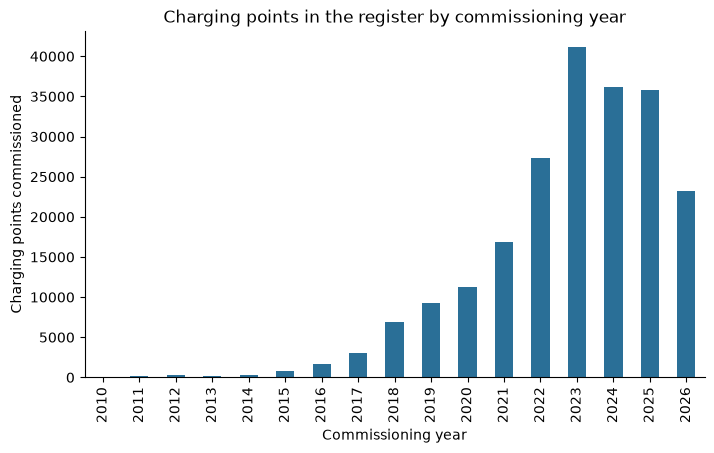

In [5]:
by_year = bnetza.dropna(subset=["commissioned"]).groupby(bnetza["commissioned"].dt.year)["n_points"].sum()
print("commissioning dates missing or unparsable:", bnetza["commissioned"].isna().sum())
print("earliest / latest:", bnetza["commissioned"].min().date(), bnetza["commissioned"].max().date())

fig, ax = plt.subplots()
by_year.loc[2010:].plot.bar(ax=ax, color="#2a6f97")
ax.set_xlabel("Commissioning year")
ax.set_ylabel("Charging points commissioned")
ax.set_title("Charging points in the register by commissioning year")
plt.show()

In [6]:
print("rows without coordinates:", bnetza[["lat", "lon"]].isna().any(axis=1).sum())
outside = ~bnetza["lat"].between(47, 55.2) | ~bnetza["lon"].between(5.5, 15.5)
print("coordinates outside Germany's bounding box:", outside.sum())
print("districts named in the register (unique):", bnetza["kreis_name"].nunique())
bnetza["kreis_name"].value_counts().head(8)

rows without coordinates: 0
coordinates outside Germany's bounding box: 1
districts named in the register (unique): 401


kreis_name
Kreisfreie Stadt Berlin               5104
Kreisfreie Stadt Hamburg              3566
Stadtkreis Stuttgart                  2408
Landkreis Region Hannover             2046
Kreisfreie Stadt München              1743
Kreisfreie Stadt Düsseldorf           1504
Kreisfreie Stadt Köln                 1498
Kreisfreie Stadt Frankfurt am Main    1374
Name: count, dtype: int64

The register names the district as text (for example `Landkreis Alb-Donau-Kreis`). It has no official district key. The key has to be built by matching names. That is the first join risk.

## 2. KBA vehicle stock (FZ 1.2)

Sheet `FZ1.2` has passenger cars (Pkw) per Zulassungsbezirk, split by fuel type. `Elektro (BEV)` is a separate column. Good. The layout needs cleaning: two header rows, state and Regierungsbezirk rows mixed in, subtotals, and the key and the name are in one text cell (`08111 STUTTGART,STADT`).

In [7]:
raw = pd.read_excel(RAW_DIR / KBA_FZ1_FILE, sheet_name="FZ1.2", header=None, skiprows=9)
cols = {3: "label", 4: "pkw_total", 5: "petrol", 6: "diesel", 7: "gas", 8: "hybrid", 9: "phev", 10: "bev", 11: "other_fuel"}
kba_all = raw[list(cols)].rename(columns=cols)

# district rows start with a 5 digit key; everything else is a header, subtotal or footnote
is_district = kba_all["label"].astype("string").str.match(r"^\d{5} ")
kba = kba_all[is_district].copy()
kba["key"] = kba["label"].str[:5]
kba["zb_name"] = kba["label"].str[6:].str.strip()
kba = kba.drop(columns="label")
print("Zulassungsbezirke:", len(kba), "| unique keys:", kba["key"].nunique())
kba.head()

Zulassungsbezirke: 400 | unique keys: 400


,pkw_total,petrol,diesel,gas,hybrid,phev,bev,other_fuel,key,zb_name
0,299197.0,172598.0,58404.0,1621.0,44686.0,17016.0,21837.0,51.0,08111,"STUTTGART,STADT"
1,265915.0,148400.0,59785.0,1351.0,37751.0,12867.0,18590.0,38.0,08115,BOEBLINGEN
2,345524.0,209322.0,81031.0,1799.0,36283.0,10732.0,17026.0,63.0,08116,ESSLINGEN
3,172252.0,103633.0,45519.0,1304.0,15085.0,3829.0,6682.0,29.0,08117,GOEPPINGEN
4,342859.0,218174.0,73981.0,1766.0,33245.0,9440.0,15642.0,51.0,08118,LUDWIGSBURG


In [8]:
# Does the sum of the districts match the national total in the file?
national = raw[raw[1].astype("string").str.strip() == "DEUTSCHLAND INSGESAMT"].iloc[0]
other = raw[raw[1].astype("string").str.strip() == "SONSTIGE"].iloc[0]
print("file total Pkw:     ", int(national[4]))
print("sum of districts:   ", int(kba["pkw_total"].sum()))
print("row 'SONSTIGE':     ", int(other[4]))
print("difference (total - districts - sonstige):", int(national[4] - kba["pkw_total"].sum() - other[4]))
print()
print("BEV total:", int(kba["bev"].sum()), "| share of all Pkw:", round(kba["bev"].sum() / kba["pkw_total"].sum() * 100, 2), "%")
print("missing values:", kba.isna().sum().sum())

file total Pkw:      49486487
sum of districts:    49436020
row 'SONSTIGE':      50467
difference (total - districts - sonstige): 0

BEV total: 2031870 | share of all Pkw: 4.11 %
missing values: 0


The district rows add up to the national total. The row `SONSTIGE` (vehicles without district) is small and is dropped.

## 3. Destatis: area and population per Kreis

In [9]:
dest_raw = pd.read_excel(RAW_DIR / DESTATIS_KREISE_FILE, sheet_name=1, header=None, skiprows=2, dtype={0: "string"})
dest = dest_raw.iloc[:, [0, 1, 2, 4, 5]]
dest.columns = ["key", "kind", "name", "area_km2", "population"]
dest = dest[dest["key"].str.fullmatch(r"\d{5}", na=False)].copy()
print("Kreise:", len(dest), "| unique keys:", dest["key"].nunique())
print("population total:", int(dest["population"].sum()))
print(dest["kind"].value_counts().to_string())
dest.head()

Kreise: 400 | unique keys: 400
population total: 83577140
kind
Landkreis           251
Kreisfreie Stadt     97
Kreis                42
Stadtkreis            9
Regionalverband       1


,key,kind,name,area_km2,population
1,01001,Kreisfreie Stadt,"Flensburg, Stadt",56.73,96326.0
2,01002,Kreisfreie Stadt,"Kiel, Landeshauptstadt",118.65,252668.0
3,01003,Kreisfreie Stadt,"Lübeck, Hansestadt",214.19,216889.0
4,01004,Kreisfreie Stadt,"Neumünster, Stadt",71.66,79809.0
5,01051,Kreis,Dithmarschen,1428.17,133460.0


## 4. Can the sources be joined?

### 4a. KBA Zulassungsbezirk key vs. Destatis district key

In [10]:
kba_keys, dest_keys = set(kba["key"]), set(dest["key"])
print("in both:         ", len(kba_keys & dest_keys))
print("only in KBA:     ", len(kba_keys - dest_keys))
print("only in Destatis:", len(dest_keys - kba_keys))
print()
print("KBA only:")
print(kba[kba["key"].isin(kba_keys - dest_keys)][["key", "zb_name", "pkw_total", "bev"]].to_string(index=False))
print()
print("Destatis only:")
print(dest[dest["key"].isin(dest_keys - kba_keys)][["key", "name", "population"]].to_string(index=False))

in both:          399
only in KBA:      1
only in Destatis: 1

KBA only:
  key     zb_name  pkw_total    bev
06415 HANAU,STADT    53997.0 2022.0

Destatis only:
  key           name  population
07235 Trier-Saarburg    148953.0


Most keys match directly. The mismatches are the cases listed above. They are known structural differences between Zulassungsbezirke and Kreise, and they decide how the cleaning step maps keys.

### 4b. Register district names vs. Destatis district names

The register has names only. Matching on the bare name is not enough: a city and its surrounding Landkreis often share a name (Ansbach, Passau, Rosenheim, Hof and others). A first attempt that ignored this matched 442 names to 401 and counted charging points twice. The match therefore uses two parts: the type (city or rural district) and the name without prefixes, suffixes and brackets.

In [11]:
CITY_PREFIXES = ("Kreisfreie Stadt ", "Stadtkreis ")


def is_city_reg(name: str) -> bool:
    return name.startswith(CITY_PREFIXES)


def norm(name: str) -> str:
    s = re.sub(r"^(Landkreis|Kreisfreie Stadt|Stadtkreis|Kreis) ", "", name)  # register prefixes
    s = s.split(",")[0]                                                       # 'Flensburg, Stadt' -> 'Flensburg'
    s = re.sub(r"\(.*?\)", "", s)                                              # '(Oldb)', '(Saale)'
    s = re.sub(r"^(Region|Städteregion|Regionalverband) ", "", s)             # 'Region Hannover'
    return re.sub(r"\s+", "", s).lower()                                      # 'a. Inn' vs 'a.Inn'


reg_names = pd.Series(bnetza["kreis_name"].unique(), name="kreis_name").to_frame()
reg_names["is_city"] = reg_names["kreis_name"].map(is_city_reg)
reg_names["norm"] = reg_names["kreis_name"].map(norm)

dest["is_city"] = dest["kind"].isin(["Kreisfreie Stadt", "Stadtkreis"])
dest["norm"] = dest["name"].map(norm)
print("duplicates in Destatis (type, name):", dest.duplicated(["is_city", "norm"]).sum())

matched = reg_names.merge(dest[["key", "is_city", "norm"]], on=["is_city", "norm"], how="left")
print("register names:", len(reg_names), "| matched:", matched["key"].notna().sum(), "| rows after merge:", len(matched))
matched[matched["key"].isna()][["kreis_name"]].to_string(index=False)

duplicates in Destatis (type, name): 0
register names: 401 | matched: 400 | rows after merge: 401


'            kreis_name\nKreisfreie Stadt Hanau'

In [12]:
unmatched = matched[matched["key"].isna()]
unmatched_points = bnetza[bnetza["kreis_name"].isin(unmatched["kreis_name"])]["n_points"].sum()
print("charging points in unmatched names:", unmatched_points, f"({unmatched_points / bnetza['n_points'].sum():.2%})")
print()
print("Destatis Kreise not hit by any register name:")
hit = matched.dropna(subset=["key"])["key"]
dest[~dest["key"].isin(hit)][["key", "name"]].to_string(index=False)

charging points in unmatched names: 255 (0.12%)

Destatis Kreise not hit by any register name:


'Empty DataFrame\nColumns: [key, name]\nIndex: []'

After the type-aware match, one register name is left: `Kreisfreie Stadt Hanau`. Destatis has no such Kreis. Hanau belongs to the Main-Kinzig-Kreis (06435). KBA lists Hanau as its own Zulassungsbezirk, while the other way round KBA merges the city of Trier and Trier-Saarburg into one Zulassungsbezirk (key 07211).

The two cases suggest these rules for the cleaning step. They are assumptions, not verified in the official documentation:

- Hanau (KBA 06415, register name) is added to Main-Kinzig-Kreis (06435).
- Trier-Saarburg (Destatis 07235) is added to the city of Trier (07211), and both are one district, as in the KBA file.

This leaves 399 districts (400 Zulassungsbezirke in the KBA file, minus Hanau). Population, area, BEV and charging points are all summed over the merged districts.

In [13]:
# Known fixes found above. In the pipeline these become an explicit, tested mapping table.
KEY_FIX = {"06415": "06435", "07235": "07211"}  # Hanau -> Main-Kinzig-Kreis, Trier-Saarburg -> Trier
matched.loc[matched["kreis_name"] == "Kreisfreie Stadt Hanau", "key"] = "06435"
assert matched["key"].notna().all()
print("register names without a key:", matched["key"].isna().sum())

register names without a key: 0


## 5. First look: electric cars vs. charging points per district

Only districts that match in both joins are used here. This is exploration, the cleaning step will handle the leftovers properly.

In [14]:
def fix_key(s: pd.Series) -> pd.Series:
    return s.replace(KEY_FIX)


points = (
    bnetza.merge(matched[["kreis_name", "key"]], on="kreis_name")
    .assign(key=lambda d: fix_key(d["key"]))
    .groupby("key")["n_points"].sum()
    .rename("charging_points")
)
cars = kba.assign(key=fix_key(kba["key"])).groupby("key", as_index=False)[["pkw_total", "bev", "phev"]].sum()
dest_fixed = (
    dest.assign(key=fix_key(dest["key"]))
    .groupby("key", as_index=False)
    .agg(name=("name", "first"), area_km2=("area_km2", "sum"), population=("population", "sum"))
)
df = (
    cars.merge(dest_fixed, on="key", validate="one_to_one")
    .merge(points, on="key", how="left")
    .assign(charging_points=lambda d: d["charging_points"].fillna(0))
)
# Hanau (KBA) was already mapped to 06435 above. The two Trier keys are one KBA row.
print("check, charging points total:", int(df["charging_points"].sum()), "vs register:", int(bnetza["n_points"].sum()))
print("check, BEV total:", int(df["bev"].sum()), "vs KBA:", int(kba["bev"].sum()))
has_points = df["charging_points"] > 0
print("districts with zero matched charging points:", (~has_points).sum())
print(df.loc[~has_points, ["key", "name", "bev", "population"]].to_string(index=False))
df["bev_per_point"] = df["bev"] / df["charging_points"].where(has_points)
df["points_per_100_bev"] = df["charging_points"] / df["bev"] * 100
df["density"] = df["population"] / df["area_km2"]
print(len(df), "districts in the joined table")
print("national BEV per charging point (joined districts):", round(df["bev"].sum() / df["charging_points"].sum(), 1))
df[["name", "bev", "charging_points", "bev_per_point", "population", "density"]].describe().round(1)

check, charging points total: 214453 vs register: 214453
check, BEV total: 2031870 vs KBA: 2031870
districts with zero matched charging points: 0
Empty DataFrame
Columns: [key, name, bev, population]
Index: []
399 districts in the joined table
national BEV per charging point (joined districts): 9.5


,bev,charging_points,bev_per_point,population,density
count,399.0,399.0,399.0,399.0,399.0
mean,5092.4,537.5,10.1,209466.5,540.5
std,5566.5,666.6,3.8,246364.3,716.0
min,421.0,52.0,2.9,33323.0,34.7
25%,2226.5,232.5,7.3,104476.0,115.9
50%,3584.0,373.0,9.8,155413.0,205.7
75%,6187.5,624.0,12.2,243977.0,664.2
max,54695.0,7833.0,29.8,3685265.0,4843.9


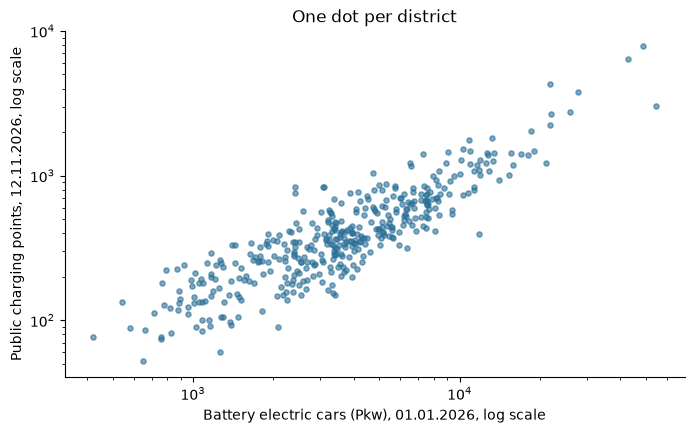

correlation of log(BEV) and log(charging points): 0.882


In [15]:
fig, ax = plt.subplots()
ax.scatter(df["bev"], df["charging_points"], s=14, alpha=0.6, color="#2a6f97")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Battery electric cars (Pkw), 01.01.2026, log scale")
ax.set_ylabel("Public charging points, 12.11.2026, log scale")
ax.set_title("One dot per district")
plt.show()
positive = df[df["charging_points"] > 0]
print("correlation of log(BEV) and log(charging points):",
      round(np.log(positive["bev"]).corr(np.log(positive["charging_points"])), 3))

In [16]:
cols = ["name", "bev", "charging_points", "bev_per_point", "density"]
print("Most BEV per charging point (candidates for underserved):")
print(df.sort_values("bev_per_point", ascending=False)[cols].head(10).round(1).to_string(index=False))
print()
print("Fewest BEV per charging point:")
print(df.sort_values("bev_per_point")[cols].head(10).round(1).to_string(index=False))

Most BEV per charging point (candidates for underserved):
                     name     bev  charging_points  bev_per_point  density
               Euskirchen 11850.0              397           29.8    162.3
             Südwestpfalz  2089.0               90           23.2     94.4
             Wolfenbüttel  3399.0              150           22.7    163.3
              Germersheim  3364.0              155           21.7    283.6
                    Kusel  1262.0               60           21.0    120.9
             Bad Dürkheim  3963.0              198           20.0    225.9
                 Biberach  6321.0              316           20.0    147.2
Altenkirchen (Westerwald)  3207.0              161           19.9    205.7
          Hochtaunuskreis  8065.0              416           19.4    501.5
      Südliche Weinstraße  3313.0              174           19.0    176.6

Fewest BEV per charging point:
                   name    bev  charging_points  bev_per_point  density
  Heilbronn, 

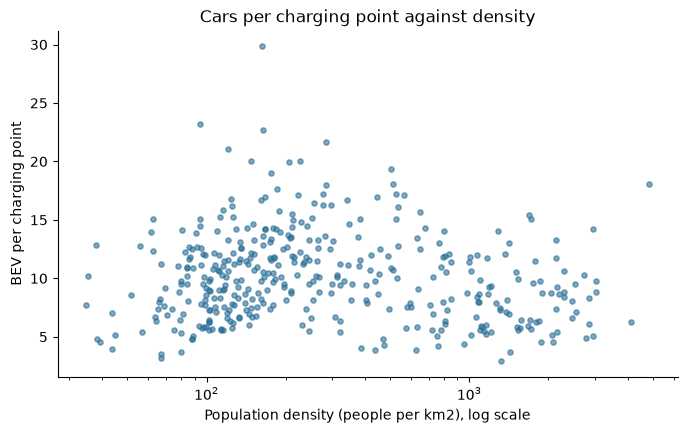

In [17]:
fig, ax = plt.subplots()
ax.scatter(df["density"], df["bev_per_point"], s=14, alpha=0.6, color="#2a6f97")
ax.set_xscale("log")
ax.set_xlabel("Population density (people per km2), log scale")
ax.set_ylabel("BEV per charging point")
ax.set_title("Cars per charging point against density")
plt.show()

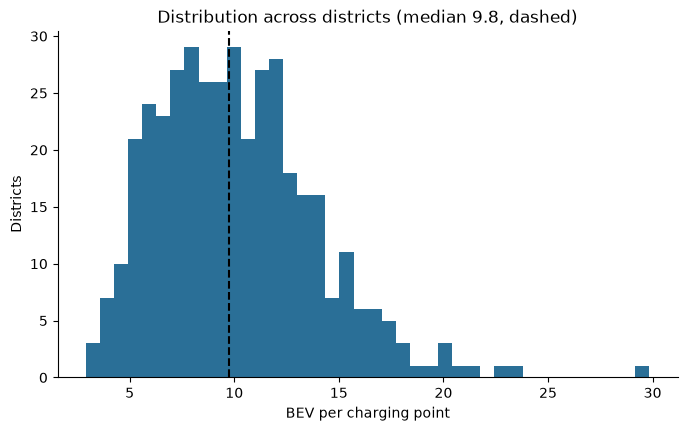

In [18]:
fig, ax = plt.subplots()
df["bev_per_point"].plot.hist(bins=40, ax=ax, color="#2a6f97")
ax.axvline(df["bev_per_point"].median(), color="black", linestyle="--")
ax.set_xlabel("BEV per charging point")
ax.set_ylabel("Districts")
ax.set_title(f"Distribution across districts (median {df['bev_per_point'].median():.1f}, dashed)")
plt.show()

## 6. Findings and open points

**Observed in the data (numbers from the cells above):**

- The register holds 119,048 stations with 214,453 charging points on 12.11.2026. 28.5% of the points are fast chargers. The number of points, not stations, is the right target.
- KBA counts 2,031,870 battery electric cars on 01.01.2026, 4.11% of all Pkw. Across the 399 districts there are 9.5 BEV per public charging point.
- Districts differ a lot: the median is 9.8 BEV per point, the range is 2.9 to 29.8. Euskirchen (29.8), Südwestpfalz (23.2) and Wolfenbüttel (22.7) have the most cars per point.
- BEV and charging points move together (correlation of the logs 0.88). A model of expected points per district is therefore reasonable. The residuals are what is interesting.
- There is no simple trend of cars per point with population density. Both dense and sparse districts show high and low values.
- Most charging points were commissioned from 2022 on. 2026 is a partial year (until November).

**Data issues found (to handle in the cleaning step):**

1. The register CSV needs `cp1252`, skips 10 header lines and uses decimal commas.
2. The register has district names, no district key. A type-aware name match fixes 400 of 401 names. `Kreisfreie Stadt Hanau` needs a manual rule. Matching without the type (city or rural district) double counts points.
3. KBA Zulassungsbezirke and Destatis Kreise differ in two places: Hanau and Trier / Trier-Saarburg.
4. Three reference dates: KBA 01.01.2026, Destatis 31.12.2024, register 12.11.2026. Cars are about 10 months older than the charging points. This biases the ratio in a fast growing market.
5. 29 stations have status "In Wartung" (not in operation). One coordinate is outside Germany. 231 stations report more than 400 kW (station totals, plausible for fast charging hubs, not verified).

**Limitations to keep in mind:**

- KBA counts cars by the place of registration, not by where they are charged. Company and leasing registrations can inflate a district.
- Through traffic, tourism and commuters are not in the data. A district can need more points than its own cars suggest.
- The register only lists points whose notification process is complete (stated by the Bundesnetzagentur), so it undercounts.

**Next:** turn the join logic into tested functions (`src/ev_gap/`), write the cleaned district table to `data/processed/`, then the baseline and the model.